# ADQL Query examples

<img style="position: absolute; right: 60px; top: 40px; height: 160px; width: 160px" src="https://datalabs.esa.int/datalab-icon/c11e47af-7ce9-4281-b3b5-475a180a256f" /> 


<div style="width: 70%;">

Copyright (c) European Space Agency, 2025.

This file is subject to the terms and conditions defined in file LICENSE.txt, which is part of this source code package. No part of the package, including this file, may be copied, modified, propagated, or distributed except according to the terms contained in the file LICENSE.txt.

</div>

**Last modified:** 2026-11-11

**Last update:** Update ADQL query examples for DR1-Foundation.

**Notebook summary**

This notebook includes the ADQL Query examples that are directly accessible from the Euclid Archive WEB interface.

1. To facilitate the navigation through this notebook, only the first 3 lines of the retrieved tables are displayed when the downloaded table contains > 10 rows. This can be easily adjusted or modified below.
2. The ADQL queries are designed to not exceed 1 minute execution time. Currently, most queries are finished in <5 seconds, but their execution time once PDR is public will increase.
3. the ADQL queries are set using the [Python f-string](https://docs.python.org/3/tutorial/inputoutput.html). This approach improves the user experience as it allows to easily modify the optional parts of the query. At the same time, I have tried to not "abuse" of this utility to balance the readibility and interactivity of the examples.

**Some useful links:**
* [Euclid DR1 data product description](https://euclid.esac.esa.int/dr/dr1/dpdd/)
* [Euclid Q1 data product description](https://euclid.esac.esa.int/dr/q1/dpdd/index.html)
* [Euclid DR1 ](https://www.cosmos.esa.int/web/euclid/euclid-dr1)
* [Astroquery.Euclid documentation content](https://astroquery.readthedocs.io/en/latest/esa/euclid/euclid.html)
* [Astroquery.EuclidClass help content](https://astroquery.readthedocs.io/en/latest/api/astroquery.esa.euclid.EuclidClass.html#astroquery.esa.euclid.EuclidClass)
* [Astropy table documentation](https://docs.astropy.org/en/stable/table/index.html)
* [Gaia Archive: TAP and ADQL](https://www.cosmos.esa.int/web/gaia-users/archive/writing-queries)



**Running the notebook:** This notebook has **read-only permissions**. You can still run and edit cells but if you would like to save your changes then you have to save the notebook to a different location - your workspace for example. The notebook is intended to be run using the **EUCLID-TOOLS kernel** that has all the necessary packages included.

***

In [2]:
# installing necessary packages
from datetime import datetime as dt
import time
from astroquery.esa.euclid.core import Euclid

import matplotlib.pyplot as plt
from astropy.table import Table
from astropy.io import fits
import os

import n_utils as utils

First let's make a folder (if not already created) to save the output files from this notebook. All the example notebooks save their outputs to this same folder in your user workspace called: `'example_notebook_outputs/'`

In [3]:
# making a folder for the output files
output_folder= '/media/user/example_notebook_outputs/'
if not os.path.exists(output_folder):
    os.makedirs(output_folder)

**Please note:** When comparing the Q1 and DR1-foundation data release content:
* some table and column names will be different
* specific examples may yield different results

It is possible to login using many different options - see the # [Euclid.login](https://astroquery.readthedocs.io/en/latest/api/astroquery.esa.euclid.EuclidClass.html#astroquery.esa.euclid.EuclidClass.login) method for details. Similarly to the archive website for safety reasons this login expires after a period of time. Once this happens the queries to the archive will fail (seemingly without reason). If you are running a personal notebook that requires you to stay logged in for longer - make sure to execute this code line again every once in a while. 

In [4]:
# Alternative ways to login; uncomment your preferred one: ===========
Euclid.login()
# Euclid.login_gui()                                          # Login via graphic interface (pop-up window)
# Euclid.login(user='<user name>', password='<password>')     # 
# Euclid.logout()

In [5]:
schema = 'dr1'   # DR1 schema. Change to "q1" to retrieve Q1 data, but please note that the target table names should be adapted accordingly. 

## 1. Cone search around NGC 6505 ("Altieri's ring") using a 0.1 degrees radius

Output size (#rows): 24,319

In [6]:
inp_coords = [267.78, 65.53] # RA & Dec - it can be updated as needed
inp_rad    = 0.1             # Cone search radius in degrees - it can be updated as needed

query = f"""SELECT right_ascension, declination, designation, object_id, vis_det, det_quality_flag, flux_detection_total, flux_vis_sersic, flux_y_sersic, flux_j_sersic, flux_h_sersic,
segmentation_map_id, segmentation_area, kron_radius, DISTANCE({inp_coords[0]}, {inp_coords[1]}, right_ascension, declination) AS dist
FROM {schema}.mer_catalogue_deep_survey
WHERE DISTANCE({inp_coords[0]}, {inp_coords[1]}, right_ascension, declination) < {inp_rad}"""

res = utils.get_query_results(Euclid, query, display_rows=3)

ADQL query: 
SELECT right_ascension, declination, designation, object_id, vis_det, det_quality_flag, flux_detection_total, flux_vis_sersic, flux_y_sersic, flux_j_sersic, flux_h_sersic,
segmentation_map_id, segmentation_area, kron_radius, DISTANCE(267.78, 65.53, right_ascension, declination) AS dist
FROM dr1.mer_catalogue_deep_survey
WHERE DISTANCE(267.78, 65.53, right_ascension, declination) < 0.1

INFO: Query finished. [astroquery.utils.tap.core]
Total runtime: 2.4 seconds
* Job output contains 24319 rows; displaying first 3 rows: 


right_ascension,declination,designation,object_id,vis_det,det_quality_flag,flux_detection_total,flux_vis_sersic,flux_y_sersic,flux_j_sersic,flux_h_sersic,segmentation_map_id,segmentation_area,kron_radius,dist
deg,deg,,NA,NA,NA,uJy,uJy,uJy,uJy,uJy,NA,pix,pix,
float64,float64,object,int64,int16,int16,float64,float64,float64,float64,float64,int64,int32,float64,float64
267.78832137868216,65.44278073725661,Euclid DR1 J175109.197+652634.01,2677883213654427807,1,0,1.4248104095458984,1.3459486961364746,1.9018778800964355,2.095604658126831,2.311379909515381,101832848017672,304,33.35429382324219,0.08728757259379001
267.80952712134035,65.44692193989805,Euclid DR1 J175114.286+652648.92,2678095271654469219,1,0,0.210839182138443,0.16991868615150452,0.22860540449619293,0.1769946813583374,0.36657413840293884,101832848018579,91,25.59398078918457,0.08397635871392627
267.7827681581236,65.4494766391831,Euclid DR1 J175107.864+652658.12,2677827681654494766,1,0,0.5302354097366333,0.5248085260391235,1.2176204919815063,1.405430793762207,1.5483657121658325,101832848019105,101,14.261641502380371,0.08053154927077616


## 2. Photometric redshift classification in a 0.1 degrees radius centred on NGC 6505 ("Altieri's ring")

Output size (#rows): 24,319

In [7]:
inp_coords = [267.78, 65.53] # RA & Dec - it can be updated as needed
inp_rad    = 0.1             # Cone search radius in degrees - it can be updated as needed

query = f"""SELECT mer.designation, mer.right_ascension, mer.declination, phz_class.*
FROM {schema}.mer_catalogue_deep_survey AS mer
JOIN {schema}.phz_classification_deep_survey AS phz_class USING (object_id)
WHERE DISTANCE({inp_coords[0]}, {inp_coords[1]}, mer.right_ascension, mer.declination) < {inp_rad}"""

res = utils.get_query_results(Euclid, query, display_rows=3, output_format='ecsv')

ADQL query: 
SELECT mer.designation, mer.right_ascension, mer.declination, phz_class.*
FROM dr1.mer_catalogue_deep_survey AS mer
JOIN dr1.phz_classification_deep_survey AS phz_class USING (object_id)
WHERE DISTANCE(267.78, 65.53, mer.right_ascension, mer.declination) < 0.1

INFO: Query finished. [astroquery.utils.tap.core]
Total runtime: 3.2 seconds
* Job output contains 24319 rows; displaying first 3 rows: 


designation,right_ascension,declination,basic_download_data_oid,calblock_id_list,configuration,data_set_release,data_set_release_part1,data_set_release_part2,data_set_release_part3,galaxy_threshold,globc_threshold,missing_band,object_id,patch_id_list,phz_classification,phz_gal_prob,phz_glob_cl_prob,phz_qso_prob,phz_star_prob,qso_threshold,star_threshold,vis_det
,deg,deg,,,NA,,,,,NA,NA,,NA,,NA,NA,NA,NA,NA,,NA,
str32,float64,float64,int64,object,int32,str6,str3,str1,int32,float64,float64,str125,int64,int64[10],int32,float64,float64,float64,float64,float64,float64,int64
Euclid DR1 J175107.026+652638.38,267.7792771103917,65.44399507290407,1273778,['CALBLOCK-F-002' 'CALBLOCK-F-003'],30,DR1_R4,DR1,--,4,0.15583078887989663,1.0,--,2677792771654439950,38 .. 151,2,0.9841621518135071,0.0,0.0,0.015269538387656212,1.0,0.8119146397026004,1
Euclid DR1 J175049.641+652720.34,267.7068394097531,65.45565122428879,1273778,['CALBLOCK-F-002' 'CALBLOCK-F-003'],30,DR1_R4,DR1,--,4,0.15583078887989663,1.0,--,2677068394654556512,38 .. 151,2,0.21321223676204681,0.0,0.0,0.7624529004096985,1.0,0.8119146397026004,1
Euclid DR1 J175028.276+652756.20,267.6178167040294,65.4656111757308,1273778,['CALBLOCK-F-002' 'CALBLOCK-F-003'],30,DR1_R4,DR1,--,4,0.15583078887989663,1.0,--,2676178167654656111,38 .. 151,2,0.7015047669410706,0.0,0.0,0.2842758595943451,1.0,0.8119146397026004,1


## 3. Count candidate stars in the phz_star_sed catalogue

Output size (#rows): 1

In [8]:
threshold = 0.9                               # Probability threshold - it can be updated as needed
inp_table = 'phz_classification_deep_survey'  # Target table          - it can be updated as needed

query = f"""SELECT count(*)
FROM {schema}.{inp_table}
WHERE phz_star_prob > {threshold}"""

res = utils.get_query_results(Euclid, query, display_rows=3)

ADQL query: 
SELECT count(*)
FROM dr1.phz_classification_deep_survey
WHERE phz_star_prob > 0.9

INFO: Query finished. [astroquery.utils.tap.core]
Total runtime: 0.8 seconds
* Job output contains 1 rows; displaying first 3 rows: 


COUNT_ALL
int64
982782


## 4. Select 10 sources with relative spectral redshift error < 10% 

Output size (#rows): 10

In [9]:
threshold = 10.0 # Redshift signal to noise - it can be updated as needed

query = f"""SELECT TOP 10 cat1.designation, cat1.object_id, cat1.right_ascension, cat1.declination, cat1.point_like_prob, cat1.det_quality_flag, cat1.spurious_flag,
cat1.flux_detection_total, cat1.mumax_minus_mag, cat1.vis_det, cat1.flux_vis_2fwhm_aper, cat2.spe_z, cat2.spe_z_err
FROM {schema}.mer_catalogue_deep_survey as cat1
JOIN {schema}.spectro_z_spe_galaxy_candidates_deep AS cat2 USING(object_id)
WHERE cat2.spe_z/cat2.spe_z_err > {threshold}"""

res = utils.get_query_results(Euclid, query, display_rows=3)

ADQL query: 
SELECT TOP 10 cat1.designation, cat1.object_id, cat1.right_ascension, cat1.declination, cat1.point_like_prob, cat1.det_quality_flag, cat1.spurious_flag,
cat1.flux_detection_total, cat1.mumax_minus_mag, cat1.vis_det, cat1.flux_vis_2fwhm_aper, cat2.spe_z, cat2.spe_z_err
FROM dr1.mer_catalogue_deep_survey as cat1
JOIN dr1.spectro_z_spe_galaxy_candidates_deep AS cat2 USING(object_id)
WHERE cat2.spe_z/cat2.spe_z_err > 10.0

INFO: Query finished. [astroquery.utils.tap.core]
Total runtime: 2.0 seconds
* Job output contains 10 rows; displaying first 3 rows: 


designation,object_id,right_ascension,declination,point_like_prob,det_quality_flag,spurious_flag,flux_detection_total,mumax_minus_mag,vis_det,flux_vis_2fwhm_aper,spe_z,spe_z_err
,NA,deg,deg,NA,NA,NA,uJy,mag / arcsec2,NA,,NA,NA
object,int64,float64,float64,float64,int16,int16,float64,float64,int16,float64,float64,float64
Euclid DR1 J173051.822+664011.31,2627159259666698075,262.7159259236162,66.6698075384954,2.3098316887626424e-05,2,0,0.9757346510887146,-0.6201438903808594,1,0.48668602108955383,1.553207278251648,0.0008687347872182727
Euclid DR1 J173051.822+664011.31,2627159259666698075,262.7159259236162,66.6698075384954,2.3098316887626424e-05,2,0,0.9757346510887146,-0.6201438903808594,1,0.48668602108955383,3.0549986362457275,0.0032285433262586594
Euclid DR1 J173051.822+664011.31,2627159259666698075,262.7159259236162,66.6698075384954,2.3098316887626424e-05,2,0,0.9757346510887146,-0.6201438903808594,1,0.48668602108955383,3.4944815635681152,0.0015314117772504687


## 5. Select top 20 brightest sources by flux_vis_sersic

Output size (#rows): 20

In [10]:
query = f"""SELECT TOP 20 designation, object_id, right_ascension, declination, flux_vis_4fwhm_aper, flux_vis_psf, flux_vis_sersic, flux_detection_total, det_quality_flag, spurious_flag, vis_det
FROM {schema}.mer_catalogue_deep_survey
WHERE NULLIF(flux_vis_sersic, 'NaN') > 0.0
ORDER BY flux_vis_sersic DESC"""

res = utils.get_query_results(Euclid, query, display_rows=3)

ADQL query: 
SELECT TOP 20 designation, object_id, right_ascension, declination, flux_vis_4fwhm_aper, flux_vis_psf, flux_vis_sersic, flux_detection_total, det_quality_flag, spurious_flag, vis_det
FROM dr1.mer_catalogue_deep_survey
WHERE NULLIF(flux_vis_sersic, 'NaN') > 0.0
ORDER BY flux_vis_sersic DESC

INFO: Query finished. [astroquery.utils.tap.core]
Total runtime: 2.5 seconds
* Job output contains 20 rows; displaying first 3 rows: 


designation,object_id,right_ascension,declination,flux_vis_4fwhm_aper,flux_vis_psf,flux_vis_sersic,flux_detection_total,det_quality_flag,spurious_flag,vis_det
,NA,deg,deg,,uJy,uJy,uJy,NA,NA,NA
object,int64,float64,float64,float64,float64,float64,float64,int16,int16,int16
Euclid DR1 J181355.135+642351.19,2734797306643975535,273.4797306274766,64.39755352829002,935.9078979492188,--,937797.9375,937798.125,386,1,1
Euclid DR1 J175833.390+663759.14,2696391290666330934,269.639129089841,66.63309346216246,36170.56640625,5165.2119140625,762118.0,762117.5,386,0,1
Euclid DR1 J181356.991+642241.28,2734874636643781344,273.4874636763333,64.37813443484443,--,--,749021.5,748888.1875,1416,0,0


## 6. Cone search to obtain the spectra of objects with 1 < z < 1.1 around a given position

Output size (#rows): 389

Note: this ADQL query contains three fields (datalabs_path, file_name, hdu_index) not included in the ADQL examples available in the WEB interface of the Euclid Archive. These fields are most relevant for users aiming to access the
spectra programmatically and mainly from ESA datalabs.

In [11]:
inp_coords = [75.0, -45.0]   # RA & Dec - it can be updated as needed
inp_rad    = 6.0             # Cone search radius in degrees - it can be updated as needed

query= f"""SELECT spec.ra_obj, spec.dec_obj, spec.source_id, spec.datalabs_path, spec.file_name, spec.hdu_index, phz.phz_median, mer.designation, mer.flux_h_4fwhm_aper
FROM {schema}.spectra_source AS spec
JOIN {schema}.phz_photo_z_deep_survey AS phz
  ON spec.source_id = phz.object_id
JOIN {schema}.mer_catalogue_deep_survey AS mer
  ON spec.source_id = mer.object_id
WHERE phz.phz_median BETWEEN 1.0 AND 1.1
AND DISTANCE(ra_obj, dec_obj, {inp_coords[0]}, {inp_coords[1]}) < {inp_rad}
ORDER BY ra_obj ASC"""

res = utils.get_query_results(Euclid, query, display_rows=3)

ADQL query: 
SELECT spec.ra_obj, spec.dec_obj, spec.source_id, spec.datalabs_path, spec.file_name, spec.hdu_index, phz.phz_median, mer.designation, mer.flux_h_4fwhm_aper
FROM dr1.spectra_source AS spec
JOIN dr1.phz_photo_z_deep_survey AS phz
  ON spec.source_id = phz.object_id
JOIN dr1.mer_catalogue_deep_survey AS mer
  ON spec.source_id = mer.object_id
WHERE phz.phz_median BETWEEN 1.0 AND 1.1
AND DISTANCE(ra_obj, dec_obj, 75.0, -45.0) < 6.0
ORDER BY ra_obj ASC

INFO: Query finished. [astroquery.utils.tap.core]
Total runtime: 12.9 seconds
* Job output contains 389 rows; displaying first 3 rows: 


ra_obj,dec_obj,source_id,datalabs_path,file_name,hdu_index,phz_median,designation,flux_h_4fwhm_aper
,,,,,,NA,,
float64,float64,int64,object,object,int64,float64,object,float64
66.6999396079388,-46.5968509501887,-666999396465968509,/data/euclid_idr1/DR1/R1/SIR_COMBINED_SPECTRA/101291171,EUC_SIR_W-COMBSPEC_101291171_20251017T100958.806157Z.fits,2489,1.0700000524520874,Euclid DR1 J042647.985-463548.66,7.761772155761719
66.7045192077367,-46.6012995608925,-667045192466012995,/data/euclid_idr1/DR1/R1/SIR_COMBINED_SPECTRA/101291171,EUC_SIR_W-COMBSPEC_101291171_20251017T100937.224559Z.fits,3207,1.059999942779541,Euclid DR1 J042649.084-463604.68,6.268165588378906
66.7144386617569,-46.6121547494888,-667144386466121547,/data/euclid_idr1/DR1/R1/SIR_COMBINED_SPECTRA/101291171,EUC_SIR_W-COMBSPEC_101291171_20251017T100937.224559Z.fits,3051,1.0,Euclid DR1 J042651.465-463643.76,19.20265007019043


### 6.1 Retrieve the spectra of the first source_id from the FITS files stored in Datalabs

To that end we use the information included in the "datalabs_path", "file_name", and "hdu_index" fields.

In [12]:
inp_row        = 0
fits_file_path = res[inp_row]['datalabs_path'] + '/' + res[inp_row]['file_name']
hdu            = res[inp_row]['hdu_index']

temp = fits.open(fits_file_path) # This contains two HDUs, we are interested in the 2nd one.
print(f'* Reading {fits_file_path}: {len(temp):,} HDUs found')
print(f'* Extracting spectra associated to HDU = {hdu}')
print()

spec_datalabs  = temp[hdu]
spec_datalabs.header

* Reading /data/euclid_idr1/DR1/R1/SIR_COMBINED_SPECTRA/101291171/EUC_SIR_W-COMBSPEC_101291171_20251017T100958.806157Z.fits: 2,499 HDUs found
* Extracting spectra associated to HDU = 2489



XTENSION= 'BINTABLE'           / binary table extension                         
BITPIX  =                    8 / 8-bit bytes                                    
NAXIS   =                    2 / 2-dimensional binary table                     
NAXIS1  =                   22 / width of table in bytes                        
NAXIS2  =                  531 / number of rows in table                        
PCOUNT  =                    0 / size of special data area                      
GCOUNT  =                    1 / one data group (required keyword)              
TFIELDS =                    6 / number of fields in each row                   
TTYPE1  = 'WAVELENGTH'         / label for field   1                            
TFORM1  = '1E      '           / data format of field: 4-byte REAL              
TUNIT1  = 'Angstrom'           / physical unit of field                         
TTYPE2  = 'SIGNAL  '           / label for field   2                            
TFORM2  = '1E      '        

### 6.3 Plot spectra

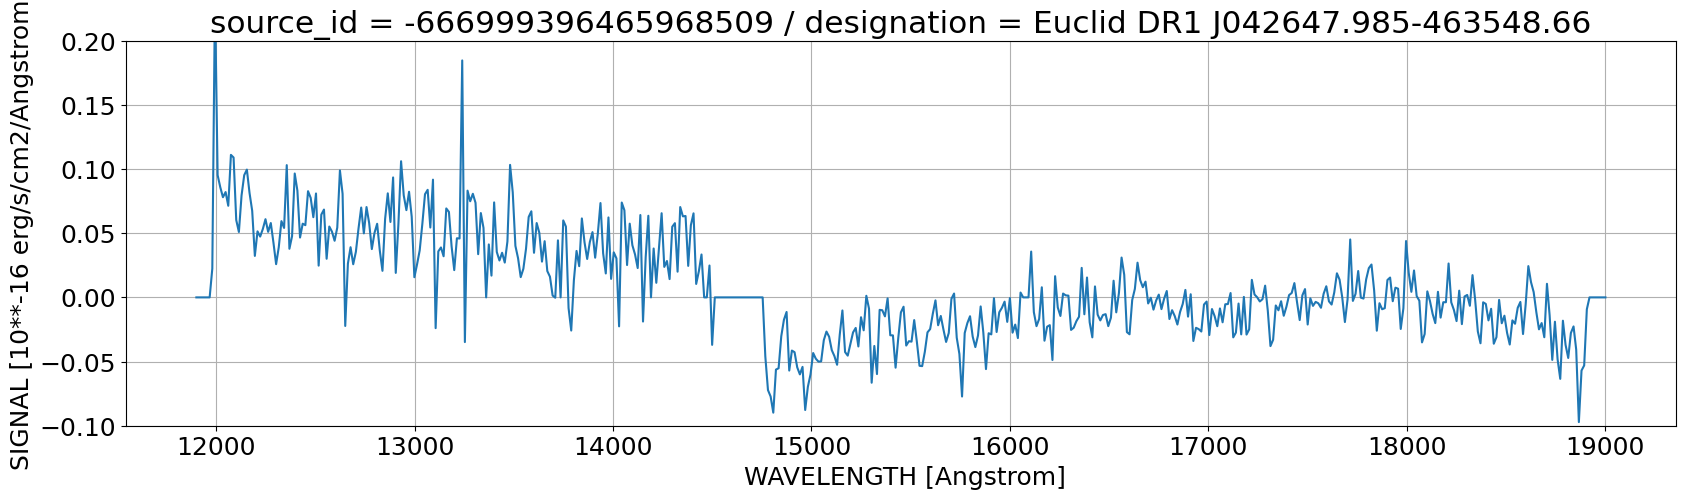

In [13]:
fontsize = 18
fig      = plt.figure(figsize=[20,5])
plt.title(f'source_id = {res[inp_row]['source_id']} / designation = {res[inp_row]['designation']}', fontsize = fontsize*1.25)
plt.plot(spec_datalabs.data['WAVELENGTH'], spec_datalabs.data['SIGNAL'], linestyle = '-')

plt.grid()
plt.ylim([-0.1,0.2])
plt.xlabel(f" WAVELENGTH [{spec_datalabs.header['TUNIT1']}]" , fontsize = fontsize)
plt.ylabel(f" SIGNAL [{spec_datalabs.header['TUNIT2']}]" , fontsize = fontsize)
plt.xticks(fontsize = fontsize)
plt.yticks(fontsize = fontsize)
plt.show()

## 7. Get mosaic information (like tile_index) for the VIS observations that include a selected target by coordinates

Output size (#rows): 120

In [15]:
inp_coords = [267.78, 65.53] # RA & Dec - it can be updated as needed
inp_rad    = 0.5             # Cone search radius in degrees - it can be updated as needed

query = f"""SELECT *, DISTANCE(ra, dec, {inp_coords[0]}, {inp_coords[1]}) AS dist
FROM {schema}.mosaic_product
WHERE DISTANCE({inp_coords[0]}, {inp_coords[1]}, ra, dec) < {inp_rad}
AND instrument_name = 'VIS'"""

res = utils.get_query_results(Euclid, query, display_rows=3)

ADQL query: 
SELECT *, DISTANCE(ra, dec, 267.78, 65.53) AS dist
FROM dr1.mosaic_product
WHERE DISTANCE(267.78, 65.53, ra, dec) < 0.5
AND instrument_name = 'VIS'

INFO: Query finished. [astroquery.utils.tap.core]
Total runtime: 0.9 seconds
* Job output contains 120 rows; displaying first 3 rows: 


activity_code,calblock_id_list,category,checksum,creation_date,crpix1,crpix2,crval1,crval2,datalabs_path,data_release_oid,data_set_release,data_size,dec,environment,file_name,file_path,filter_name,first_observation_date_time,first_type,fov,instrument_name,last_observation_date_time,mosaic_product_oid,observation_id_list,patch_id_list,processing_mode,product_id,product_type,provenance_id,published,purpose,ra,reference_observation_date_time,release_date,release_name,second_type,stc_s,technique,tile_index,to_be_published,version,xml_file_content,zero_point,zero_point_error,dist
object,object,object,object,object,float64,float64,float64,float64,object,int64,object,float64,float64,object,object,object,object,object,object,object,object,object,int64,object,object,object,object,object,int64,int32,object,float64,object,object,object,object,object,object,int64,int32,int32,object,float64,float64,float64
,CALBLOCK-F-003,SCIENCE,173b70548970f60835898690fcaf77f1,2025-07-03T21:21:49.047,9600.0,9720.0,267.3807789,65.4983,/data/euclid_idr1/DR1/R1/MER/102158889/VIS,4,DR1_R1,-32.0,65.4983,DR1,EUC_MER_BGSUB-MOSAIC-VIS_TILE102158889-2A351_20250701T131024.752713Z_00.00.fits,/data/euclid/repository_dr1/DR1/R1/MER/102158889/VIS,VIS,2024-06-13T02:48:04.919,STD,[268.01711050138965 65.22698537773368 266.74438101261455 65.22698509761862\n 266.7310851576081 65.76691932015984 268.0304049717605 65.7669196073578],VIS,2024-06-13T22:10:10.045,16245,2055 2059 2060 2070,38,WIDE,MER_ProcessTile_EUCLID_2.0.25-DATA_RELEASE_DEEP-pcasenov-PLAN-000000-O5UM1RMG-20250630-140802-506-compressed_mosaics-0,DpdMerBksMosaic,35,0,DATA_RELEASE_DEEP,267.3807789,2024-06-13T08:47:24.458,,DR1_R1,SKY,Polygon J2000 268.01711050138994 65.22698537773358 266.7443810126148 65.22698509761858 266.73108515760794 65.76691932015997 268.03040497176073 65.76691960735793,IMAGE,102158889,1,1,org.postgresql.jdbc.PgSQLXML@7fccab37,24.5,0.1,0.1684734751975338
,CALBLOCK-F-002 CALBLOCK-F-003,SCIENCE,fc5e8d08a685bcb8b14640a0b5a79a31,2025-08-25T03:25:07.378,5100.0,5100.0,266.7892285004,65.25,/data/euclid_idr1/DR1/R1/MER/101832242/VIS,4,DR1_R1,-32.0,65.25,DR1,EUC_MER_BGSUB-MOSAIC-VIS_TILE101832242-19E454_20250824T081115.559787Z_00.00.fits,/data/euclid/repository_dr1/DR1/R1/MER/101832242/VIS,VIS,2024-06-13T07:43:48.951,STD,[267.12573519995397 65.10798410557334 266.45265580771803 65.10798395757318\n 266.44902644927816 65.39128399517811 267.12936384680427 65.39128414511602],VIS,2025-05-12T10:20:42.218,127600,2059 2060 2070 2105 2106 2109 2217 2218 2705 2711 2989 2998 2999 3314 3315 3325 4988 4996 5556 5565 5566 6154 6158 6159 6873 7802 7803,"38,39,44,49,57,64,99,114,130,151,171",DEEP,MER_ProcessTile_EUCLID_2.0.32-DATA_RELEASE_DEEP-trochequ-PLAN-000002-HI3W1107-20250728-172841-148-RETRY-250823124312-compressed_mosaics-0,DpdMerBksMosaic,40,0,DATA_RELEASE_DEEP,266.7892285004,2024-08-05T03:06:29.323,,DR1_R1,SKY,Polygon J2000 267.125735199954 65.1079841055734 266.45265580771803 65.10798395757313 266.4490264492784 65.3912839951784 267.12936384680444 65.39128414511596,IMAGE,101832242,1,1,org.postgresql.jdbc.PgSQLXML@493704f5,24.5,0.1,0.4986251813590178
,CALBLOCK-F-002,SCIENCE,26b5cc2fb5154867913e5f2501d4a309,2025-07-21T13:28:00.483,9600.0,9720.0,267.3807789,65.4983,/data/euclid_idr1/DR1/R1/MER/102158889/VIS,4,DR1_R1,-32.0,65.4983,DR1,EUC_MER_BGSUB-MOSAIC-VIS_TILE102158889-4DB06F_20250719T083756.770907Z_00.00.fits,/data/euclid/repository_dr1/DR1/R1/MER/102158889/VIS,VIS,2024-06-15T05:20:58.25,STD,[268.01711050138965 65.22698537773368 266.74438101261455 65.22698509761862\n 266.7310851576081 65.76691932015984 268.0304049717605 65.7669196073578],VIS,2024-06-15T22:15:09.36,85246,2096 2105 2106 2109,39,WIDE,MER_ProcessTile_EUCLID_2.0.25-DATA_RELEASE_DEEP-pcasenov-PLAN-000000-XLA2XX9U-20250630-140802-505-compressed_mosaics-0,DpdMerBksMosaic,35,0,DATA_RELEASE_DEEP,267.3807789,2024-06-15T17:29:46.829,,DR1_R1,SKY,Polygon J2000 268.01711050138994 65.22698537773358 266.7443810126148 65.22698509761858 266.73108515760794 65.76

## 8. Photometric object classification for the sources that are likely galaxies detected in tile_index = 102158889

Output size (#rows): 34,955

In [16]:
tile_index = 101274909   # Tile index - it can be updated as needed
threshold  = 0.8         # Cone search radius in degrees - it can be updated as needed


query = f"""SELECT mer_cat.right_ascension, mer_cat.declination, mer_cat.segmentation_map_id, mer_cat.tile_index, mer_cat.designation, phz_class.object_id, phz_class.phz_star_prob, phz_class.phz_gal_prob, phz_class.phz_qso_prob
FROM {schema}.mer_catalogue_deep_survey AS mer_cat
JOIN {schema}.phz_classification_deep_survey AS phz_class USING (object_id)
WHERE mer_cat.tile_index = {tile_index}
AND phz_class.phz_gal_prob > {threshold}
ORDER BY phz_class.phz_gal_prob DESC"""

res = utils.get_query_results(Euclid, query, display_rows=3)

ADQL query: 
SELECT mer_cat.right_ascension, mer_cat.declination, mer_cat.segmentation_map_id, mer_cat.tile_index, mer_cat.designation, phz_class.object_id, phz_class.phz_star_prob, phz_class.phz_gal_prob, phz_class.phz_qso_prob
FROM dr1.mer_catalogue_deep_survey AS mer_cat
JOIN dr1.phz_classification_deep_survey AS phz_class USING (object_id)
WHERE mer_cat.tile_index = 101274909
AND phz_class.phz_gal_prob > 0.8
ORDER BY phz_class.phz_gal_prob DESC

INFO: Query finished. [astroquery.utils.tap.core]
Total runtime: 2.3 seconds
* Job output contains 34955 rows; displaying first 3 rows: 


right_ascension,declination,segmentation_map_id,tile_index,designation,object_id,phz_star_prob,phz_gal_prob,phz_qso_prob
deg,deg,NA,,,NA,NA,NA,NA
float64,float64,int64,int64,object,int64,float64,float64,float64
58.21305175923604,-50.63720490287855,101274909052776,101274909,Euclid DR1 J035251.132-503813.94,-582130517506372049,0.0026106571312993765,0.9977844953536987,0.0
58.16568377193396,-50.764209328987384,101274909025869,101274909,Euclid DR1 J035239.764-504551.15,-581656837507642093,0.0028046779334545135,0.9974558353424072,0.0
58.36370916067431,-50.764776239649755,101274909025722,101274909,Euclid DR1 J035327.290-504553.19,-583637091507647762,0.002516159787774086,0.997412383556366,0.0


## 9. Find the mosaic FITS files that contain VIS observations of a given sky region (projected circle of 1 arcminute radius centred at ra, dec = 54.2092 deg, -28.0792 deg)

Output size (#rows): 3

In [17]:
inp_coords = [54.2092, -28.0792] # RA & Dec - it can be updated as needed
inp_rad    = 1/60.               # CIRCLE search radius in degrees - it can be updated as needed

query = f"""SELECT file_name, file_path, datalabs_path, instrument_name, filter_name, ra, dec, creation_date, product_type, patch_id_list, tile_index
FROM {schema}.mosaic_product
WHERE instrument_name = 'VIS' AND INTERSECTS(CIRCLE({inp_coords[0]}, {inp_coords[1]}, {inp_rad}), fov)=1"""

res = utils.get_query_results(Euclid, query, display_rows=3)

ADQL query: 
SELECT file_name, file_path, datalabs_path, instrument_name, filter_name, ra, dec, creation_date, product_type, patch_id_list, tile_index
FROM dr1.mosaic_product
WHERE instrument_name = 'VIS' AND INTERSECTS(CIRCLE(54.2092, -28.0792, 0.016666666666666666), fov)=1

INFO: Query finished. [astroquery.utils.tap.core]
Total runtime: 0.8 seconds
* Job output contains 3 rows; displaying first 3 rows: 


file_name,file_path,datalabs_path,instrument_name,filter_name,ra,dec,creation_date,product_type,patch_id_list,tile_index
object,object,object,object,object,float64,float64,object,object,object,int64
EUC_MER_BGSUB-MOSAIC-VIS_TILE102044187-7C7528_20250727T022712.564310Z_00.00.fits,/data/euclid/repository_dr1/DR1/R2/MER/102044187/VIS,/data/euclid_idr1/DR1/R2/MER/102044187/VIS,VIS,VIS,54.1143334,-28.0,2025-07-28T21:47:00.774,DpdMerBksMosaic,59,102044187
EUC_MER_BGSUB-MOSAIC-VIS_TILE101375810-F6FF2E_20250729T162837.328403Z_00.00.fits,/data/euclid/repository_dr1/DR1/R2/MER/101375810/VIS,/data/euclid_idr1/DR1/R2/MER/101375810/VIS,VIS,VIS,54.23804578514,-28.0,2025-07-30T04:30:36.301,DpdMerBksMosaic,"58,59",101375810
EUC_MER_BGSUB-MOSAIC-VIS_TILE102044187-4D0CB5_20250706T060715.289739Z_00.00.fits,/data/euclid/repository_dr1/DR1/R1/MER/102044187/VIS,/data/euclid_idr1/DR1/R1/MER/102044187/VIS,VIS,VIS,54.1143334,-28.0,2025-07-08T16:18:28.337,DpdMerBksMosaic,58,102044187


## 10. Find DR1 counterparts to a Q1 sample

Output size (#rows): 3

In [22]:
query = f"""WITH q1_sample AS (SELECT right_ascension AS q1_ra, declination AS q1_dec, object_id AS q1_object_id
FROM q1.mer_catalogue
WHERE DISTANCE(267.78, 65.53, right_ascension, declination) < 0.1)

SELECT dr1.designation, dr1.object_id, dr1.right_ascension, dr1.declination, q1.q1_object_id, q1.q1_ra, q1.q1_dec, DISTANCE(q1.q1_ra, q1.q1_dec, dr1.right_ascension, dr1.declination)*3600 AS separation_arcsec
FROM dr1.mer_catalogue_deep_survey AS dr1
JOIN q1_sample AS q1
ON DISTANCE(q1.q1_ra, q1.q1_dec, dr1.right_ascension, dr1.declination) < 1./3600.
ORDER BY dr1.object_id ASC
"""

res = utils.get_query_results(Euclid, query, display_rows=3)

ADQL query: 
WITH q1_sample AS (SELECT right_ascension AS q1_ra, declination AS q1_dec, object_id AS q1_object_id
FROM q1.mer_catalogue
WHERE DISTANCE(267.78, 65.53, right_ascension, declination) < 0.1)

SELECT dr1.designation, dr1.object_id, dr1.right_ascension, dr1.declination, q1.q1_object_id, q1.q1_ra, q1.q1_dec, DISTANCE(q1.q1_ra, q1.q1_dec, dr1.right_ascension, dr1.declination)*3600 AS separation_arcsec
FROM dr1.mer_catalogue_deep_survey AS dr1
JOIN q1_sample AS q1
ON DISTANCE(q1.q1_ra, q1.q1_dec, dr1.right_ascension, dr1.declination) < 1./3600.
ORDER BY dr1.object_id ASC


INFO: Query finished. [astroquery.utils.tap.core]
Total runtime: 1.7 seconds
* Job output contains 12744 rows; displaying first 3 rows: 


designation,object_id,right_ascension,declination,q1_object_id,q1_ra,q1_dec,separation_arcsec
,NA,deg,deg,NA,deg,deg,
object,int64,float64,float64,int64,float64,float64,float64
Euclid DR1 J175009.500+653116.91,2675395858655213640,267.53958580005656,65.52136406372216,2675395565655214045,267.5395565373916,65.5214045661906,0.15220243833506636
Euclid DR1 J175009.500+653116.91,2675395858655213640,267.53958580005656,65.52136406372216,2675396182655211476,267.53961820842454,65.52114768681683,0.780455525125356
Euclid DR1 J175009.504+653215.28,2675396005655375789,267.53960051920427,65.53757892055252,2675396119655375821,267.5396119736747,65.53758219392085,0.020747183785195192
